Analyze training time vs. performance trade-offs by manually tracking runtime, memory consumption, and computational efficiency of different models, identifying optimal model complexity for real-world deployment.

In [1]:
import pandas as pd
import numpy as np
import time
import tracemalloc
import os
import joblib
import tempfile

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].copy()

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()

X = df[features].to_numpy(dtype=float)
y = df[target].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10,
        class_weight="balanced", random_state=42
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(class_weight="balanced", random_state=42)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Models to benchmark:", len(models))

Training samples: 63
Test samples: 16
Models to benchmark: 5


In [2]:
def calculate_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    return accuracy, precision, recall, f1

In [3]:
from sklearn.base import clone

try:
    import psutil
    process = psutil.Process(os.getpid())
    memory_available = True
except ImportError:
    memory_available = False

benchmark_results = []
trained_models = {}

for name, original_model in models.items():
    model = clone(original_model)

    # Measure memory before training
    if memory_available:
        memory_before = process.memory_info().rss / (1024 ** 2)

    tracemalloc.start()
    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time
    current_memory, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # Measure process memory after training
    if memory_available:
        memory_after = process.memory_info().rss / (1024 ** 2)
        memory_change = memory_after - memory_before
    else:
        memory_change = np.nan

    # Measure prediction latency over repeated batches
    model.predict(X_test[:1])  # Warm-up
    prediction_times = []

    for _ in range(5):
        start_time = time.perf_counter()
        model.predict(X_test)
        prediction_times.append(time.perf_counter() - start_time)

    avg_prediction_time = np.mean(prediction_times)
    latency_per_sample_ms = (
        avg_prediction_time / len(X_test) * 1000
    )

    # Measure compressed model file size
    with tempfile.TemporaryDirectory() as temp_dir:
        model_file = Path(temp_dir) / "model.joblib"
        joblib.dump(model, model_file, compress=3)
        model_size_kb = model_file.stat().st_size / 1024

    # Evaluate predictions
    predictions = model.predict(X_test)
    accuracy, precision, recall, f1 = calculate_metrics(
        y_test, predictions
    )

    trained_models[name] = model

    benchmark_results.append({
        "Model": name,
        "Training Time (s)": training_time,
        "Prediction Time (s)": avg_prediction_time,
        "Latency (ms/sample)": latency_per_sample_ms,
        "Peak Python Memory (MB)": peak_memory / (1024 ** 2),
        "RSS Change (MB)": memory_change,
        "Model Size (KB)": model_size_kb,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(
        name,
        "| Train:", round(training_time, 4), "s",
        "| Predict:", round(avg_prediction_time, 4), "s",
        "| F1:", round(f1, 4)
    )

Logistic Regression | Train: 0.0521 s | Predict: 0.0015 s | F1: 0.8
Decision Tree | Train: 0.0262 s | Predict: 0.0005 s | F1: 0.8333
Random Forest | Train: 2.6196 s | Predict: 0.0302 s | F1: 0.8333
SVM | Train: 0.0249 s | Predict: 0.0015 s | F1: 0.8333
KNN | Train: 0.014 s | Predict: 0.003 s | F1: 0.8148


In [4]:
benchmark_df = pd.DataFrame(benchmark_results)

print(
    benchmark_df.sort_values(
        "F1 Score", ascending=False
    ).round(4).to_string(index=False)
)

              Model  Training Time (s)  Prediction Time (s)  Latency (ms/sample)  Peak Python Memory (MB)  RSS Change (MB)  Model Size (KB)  Accuracy  Precision  Recall  F1 Score
      Decision Tree             0.0262               0.0005               0.0289                   0.0212           0.2227           1.2373    0.7500     0.8333  0.8333    0.8333
                SVM             0.0249               0.0015               0.0938                   0.0249           0.0977           3.1826    0.7500     0.8333  0.8333    0.8333
      Random Forest             2.6196               0.0302               1.8850                   0.1114           0.2266          25.6025    0.7500     0.8333  0.8333    0.8333
                KNN             0.0140               0.0030               0.1885                   0.0227           0.0703           3.5020    0.6875     0.7333  0.9167    0.8148
Logistic Regression             0.0521               0.0015               0.0951                   0.0567

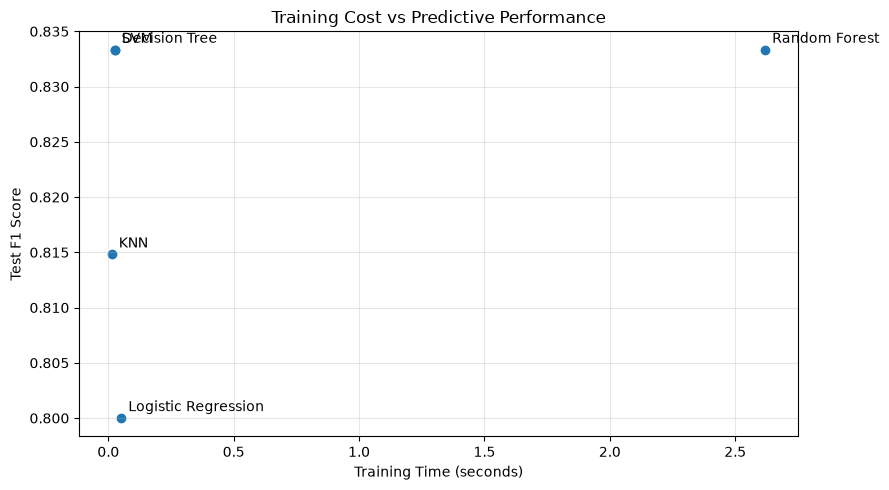

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    benchmark_df["Training Time (s)"],
    benchmark_df["F1 Score"]
)

for _, row in benchmark_df.iterrows():
    plt.annotate(
        row["Model"],
        (row["Training Time (s)"], row["F1 Score"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Training Time (seconds)")
plt.ylabel("Test F1 Score")
plt.title("Training Cost vs Predictive Performance")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

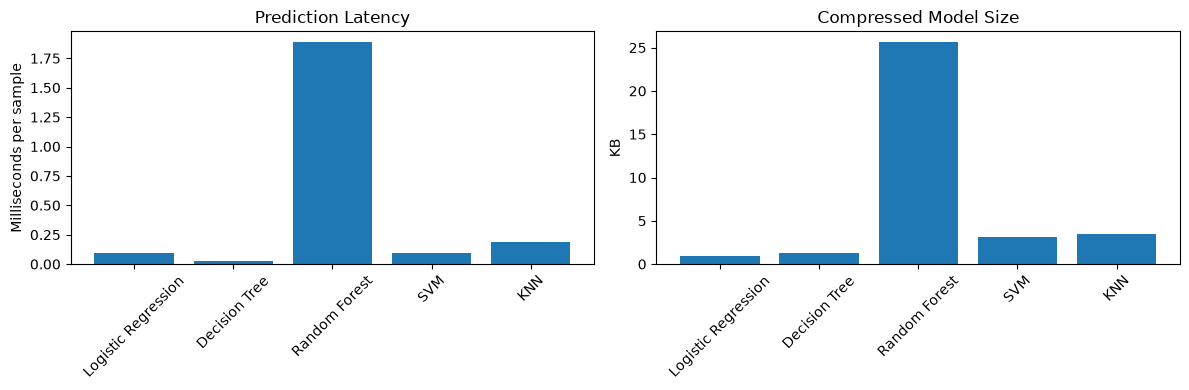

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    benchmark_df["Model"],
    benchmark_df["Latency (ms/sample)"]
)
axes[0].set_title("Prediction Latency")
axes[0].set_ylabel("Milliseconds per sample")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(
    benchmark_df["Model"],
    benchmark_df["Model Size (KB)"]
)
axes[1].set_title("Compressed Model Size")
axes[1].set_ylabel("KB")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [9]:
best_f1 = benchmark_df["F1 Score"].max()

candidates = benchmark_df[
    benchmark_df["F1 Score"] >= best_f1 - 0.02
].copy()

candidates = candidates.sort_values(
    ["Latency (ms/sample)", "Model Size (KB)"]
)

selected_name = candidates.iloc[0]["Model"]
selected_row = candidates.iloc[0]

print("Suggested efficient candidate:", selected_name)
print("Test F1 Score:", round(selected_row["F1 Score"], 4))
print("Training Time (s):", round(selected_row["Training Time (s)"], 4))
print("Latency (ms/sample):", round(selected_row["Latency (ms/sample)"], 4))
print("Model Size (KB):", round(selected_row["Model Size (KB)"], 2))

Suggested efficient candidate: Decision Tree
Test F1 Score: 0.8333
Training Time (s): 0.0262
Latency (ms/sample): 0.0289
Model Size (KB): 1.24


In [10]:
best_training = benchmark_df.loc[
    benchmark_df["Training Time (s)"].idxmin()
]
best_latency = benchmark_df.loc[
    benchmark_df["Latency (ms/sample)"].idxmin()
]
smallest_model = benchmark_df.loc[
    benchmark_df["Model Size (KB)"].idxmin()
]
best_f1_row = benchmark_df.loc[
    benchmark_df["F1 Score"].idxmax()
]

print("Fastest training:", best_training["Model"])
print("Fastest prediction:", best_latency["Model"])
print("Smallest saved model:", smallest_model["Model"])
print("Highest test F1:", best_f1_row["Model"])

print("\nDeployment analysis:")
print(
    "The preferred model depends on the balance between predictive "
    "performance, prediction latency, memory, and storage."
)
print(
    "For low-latency applications, prioritize prediction time. "
    "For memory-constrained systems, prioritize RSS and model size."
)
print(
    "For heart disease prediction, do not sacrifice recall and "
    "false-negative analysis solely to reduce computational cost."
)

Fastest training: KNN
Fastest prediction: Decision Tree
Smallest saved model: Logistic Regression
Highest test F1: Decision Tree

Deployment analysis:
The preferred model depends on the balance between predictive performance, prediction latency, memory, and storage.
For low-latency applications, prioritize prediction time. For memory-constrained systems, prioritize RSS and model size.
For heart disease prediction, do not sacrifice recall and false-negative analysis solely to reduce computational cost.
